# Example Fits Related to EmFit

Ragadeepika Pucha, Stéphanie Juneau, Arjun Dey, and others ...

This Notebook provides examples of EmFit fits that are "good" fits.

In [1]:
import numpy as np

from astropy.io import fits
from astropy.table import Table, join, Column, vstack

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/EmFit/py/')
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import emline_fitting as emfit
import spec_utils
import plot_utils

import bpt
import utils

import matplotlib.pyplot as plt

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':28,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':3.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
def normal_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for default cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select [OIII] region 
    oiii_lam = (lam_rest >= 4900)&(lam_rest <= 5050)
    lam_oiii = lam_rest[oiii_lam]
    flam_oiii = flam_rest[oiii_lam]

    ## Select [NII] + Ha region 
    nii_lam = (lam_rest >= 6470)&(lam_rest <= 6660)
    lam_nii = lam_rest[nii_lam]
    flam_nii = flam_rest[nii_lam]

    ## Select Hb region 
    hb_lam = (lam_rest >= 4800)&(lam_rest <= 4930)
    lam_hb = lam_rest[hb_lam]
    flam_hb = flam_rest[hb_lam]

    ## Select [SII] region 
    sii_lam = (lam_rest >= 6650)&(lam_rest <= 6800)
    lam_sii = lam_rest[sii_lam]
    flam_sii = flam_rest[sii_lam]

    ## Construct Fits
    fits_def = emfit.construct_fits_from_table.normal_fit(table, index)
    ## Separate the fits 
    hb_fit, oiii_fit, nii_ha_fit, sii_fit = fits_def
    ## Reduced chi2 values from the table
    rchi2_hb = table['HB_RCHI2'].data[index]
    rchi2_oiii = table['OIII_RCHI2'].data[index]
    rchi2_nii_ha = table['NII_HA_RCHI2'].data[index]
    rchi2_sii = table['SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 8))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb
    hb = fig.add_subplot(gs[0:4, 0:4])
    hb_res = fig.add_subplot(gs[4:, 0:4], sharex = hb)

    ## Subplots for [OIII]
    oiii = fig.add_subplot(gs[0:4, 4:8])
    oiii_res = fig.add_subplot(gs[4:, 4:8], sharex = oiii)

    ## Subplots for [NII]+Ha
    ha = fig.add_subplot(gs[0:4, 8:12])
    ha_res = fig.add_subplot(gs[4:, 8:12], sharex = ha)

    ## Subplots for [SII]
    sii = fig.add_subplot(gs[0:4, 12:])
    sii_res = fig.add_subplot(gs[4:, 12:], sharex = sii)

    ############################################################################################
    ############################## Hb spectra + models #########################################

    hb.plot(lam_hb, flam_hb, color = 'k')
    hb.plot(lam_hb, hb_fit(lam_hb), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb fits
    n_hb = hb_fit.n_submodels

    ## Hb continuum
    hb_cont = hb_fit['hb_cont'].amplitude.value

    ## Narrow component of Hb
    hb.plot(lam_hb, hb_fit['hb_n'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Outflow component of Hb, if available 
    if ('hb_out' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_out'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Broad component of Hb, if available
    if ('hb_b' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_b'](lam_hb) + hb_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    hb.annotate('$H\\beta$', xy = (0.03, 0.9), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')
    hb.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_hb, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ## Hb fit residuals
    res_hb = (flam_hb - hb_fit(lam_hb))/flam_hb
    hb_res.scatter(lam_hb, res_hb, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'grey', ls = ':')
    hb_res.set(yticks = [0])
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10])

    ############################################################################################
    ############################## [OIII] spectra + models #####################################

    oiii.plot(lam_oiii, flam_oiii, color = 'k')
    oiii.plot(lam_oiii, oiii_fit(lam_oiii), color = 'r', lw = 4.0, ls = '--')
    oiii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(oiii.get_xticklabels(), visible = False)

    n_oiii = oiii_fit.n_submodels
    names_oiii = oiii_fit.submodel_names

    ### [OIII] continuum
    oiii_cont = oiii_fit['oiii_cont'].amplitude.value

    ## [OIII]4959,5007 components, including outflow components, if available
    for ii in range(1, n_oiii):
        oiii.plot(lam_oiii, oiii_fit[names_oiii[ii]](lam_oiii) + oiii_cont, color = 'orange', lw = 2.0)

    ## Rchi2 value
    oiii.annotate('[OIII]4959,5007', xy = (0.03, 0.9), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()),\
                  fontsize = 28, color = 'k')
    oiii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_oiii, 2)), \
                  xy = (0.03, 0.8), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()), \
                  fontsize = 28, color = 'k')

    ## [OIII] fit residuals
    res_oiii = (flam_oiii - oiii_fit(lam_oiii))/flam_oiii
    oiii_res.scatter(lam_oiii, res_oiii, color = 'k', marker = '.', alpha = 0.7)
    oiii_res.axhline(0.0, color = 'k', ls = ':')
    oiii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [NII]+Ha spectra + models ###################################

    ha.plot(lam_nii, flam_nii, color = 'k')
    ha.plot(lam_nii, nii_ha_fit(lam_nii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)    

    ## [NII] + Ha continuum
    nii_ha_cont = nii_ha_fit['nii_ha_cont'].amplitude.value

    ## Plot narrow components
    ha.plot(lam_nii, nii_ha_fit['nii6548'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['nii6583'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['ha_n'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Outflow components, if available
    if ('nii6548_out' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['nii6548_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['nii6583_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['ha_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Broad component, if available
    if ('ha_b' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['ha_b'](lam_nii) + nii_ha_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    ha.annotate('$H\\alpha$ + [NII]6548,6583', xy = (0.03, 0.9),\
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')
    ha.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_nii_ha, 2)),\
                xy = (0.03, 0.8), xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')

    ## [NII]+Ha fit residuals
    res_nii = (flam_nii - nii_ha_fit(lam_nii))/flam_nii
    ha_res.scatter(lam_nii, res_nii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [SII] spectra + models ######################################

    sii.plot(lam_sii, flam_sii, color = 'k')
    sii.plot(lam_sii, sii_fit(lam_sii), color = 'r', lw = 4.0, ls = '--')
    sii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(sii.get_xticklabels(), visible = False)

    ## [SII] fits
    n_sii = sii_fit.n_submodels
    names_sii = sii_fit.submodel_names

    ## [SII] continuum
    sii_cont = sii_fit['sii_cont'].amplitude.value

    ## All components of [SII], outflow components included, if available
    for ii in range(1, n_sii):
        sii.plot(lam_sii, sii_fit[names_sii[ii]](lam_sii) + sii_cont, color = 'orange')

    ## Rchi2 value
    sii.annotate('[SII]6716, 6731', xy = (0.03, 0.9),\
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')
    sii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_sii, 2)), xy = (0.03, 0.8), \
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')

    ## [SII] fit residuals
    res_sii = (flam_sii - sii_fit(lam_sii))/flam_sii
    sii_res.scatter(lam_sii, res_sii, color = 'k', marker = '.', alpha = 0.7)
    sii_res.axhline(0.0, color = 'k', ls = ':')
    sii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])
    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [4]:
def extreme_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for extreme BL cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select Hb+[OIII] region
    hb_oiii_lam = (lam_rest >= 4700)&(lam_rest <= 5100)
    lam_hb_oiii = lam_rest[hb_oiii_lam]
    flam_hb_oiii = flam_rest[hb_oiii_lam]

    ## Select [NII]+Ha+[SII] region
    nii_ha_sii_lam = (lam_rest >= 6300)&(lam_rest <= 6800)
    lam_nii_ha_sii = lam_rest[nii_ha_sii_lam]
    flam_nii_ha_sii = flam_rest[nii_ha_sii_lam]

    ## Construct Fits
    fits_ebl = emfit.construct_fits_from_table.extreme_fit(table, index)
    ## Separate the fits 
    hb_oiii_fit, nii_ha_sii_fit = fits_ebl
    ## Rchi2 values
    hb_oiii_rchi2 = table['HB_OIII_RCHI2'].data[index]
    nii_ha_sii_rchi2 = table['NII_HA_SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 10))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb+[OIII]
    hb = fig.add_subplot(gs[0:4, 0:8])
    hb_res = fig.add_subplot(gs[4:, 0:8], sharex = hb)

    ## Subplots for [NII]+Ha+[SII]
    ha = fig.add_subplot(gs[0:4, 8:])
    ha_res = fig.add_subplot(gs[4:, 8:], sharex = ha)

    ############################################################################################
    ############################ Hb + [OIII] spectra and models ################################

    hb.plot(lam_hb_oiii, flam_hb_oiii, color = 'k')
    hb.plot(lam_hb_oiii, hb_oiii_fit(lam_hb_oiii), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb + [OIII] continuum
    hb_cont = hb_oiii_fit['hb_oiii_cont'].amplitude.value

    ## Narrow components
    hb.plot(lam_hb_oiii, hb_oiii_fit['hb_n'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)

    if ('hb_b' in hb_oiii_fit.submodel_names):
        ## Broad component
        hb.plot(lam_hb_oiii, hb_oiii_fit['hb_b'](lam_hb_oiii) + hb_cont, color = 'blue', lw = 2.0)

    ## Outflow components, if available
    if ('oiii5007_out' in hb_oiii_fit.submodel_names):
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)

    hb.annotate('$\\rm H\\beta + [OIII]4959,5007$', xy = (0.03, 0.9), \
               xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    hb.annotate('$\chi^{2}_{red}$ = '+str(round(hb_oiii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## Hb + [OIII] Fit residuals
    res_hb_oiii = (flam_hb_oiii - hb_oiii_fit(lam_hb_oiii))/flam_hb_oiii
    hb_res.scatter(lam_hb_oiii, res_hb_oiii, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'k', ls = ':')
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10,10], yticks = [0])

    ############################################################################################
    ###################### [NII] + Ha + [SII] spectra and models ###############################

    ha.plot(lam_nii_ha_sii, flam_nii_ha_sii, color = 'k')
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit(lam_nii_ha_sii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)

    ## [NII]+Ha+[SII] continuum
    ha_cont = nii_ha_sii_fit['nii_ha_sii_cont'].amplitude.value

    ## Narrow components
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_n'](lam_nii_ha_sii) + ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6548'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6583'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6716'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6731'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)


    if ('ha_b' in nii_ha_sii_fit.submodel_names):
        ## Broad component
        ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_b'](lam_nii_ha_sii) + ha_cont, \
                color = 'blue', lw = 2.0)
 
    ha.annotate('$\\rm [NII]6548,6583 + H\\alpha + [SII]6716,6731$', xy = (0.03, 0.9), \
               xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ha.annotate('$\chi^{2}_{red}$ = '+str(round(nii_ha_sii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## [NII]+Ha+[SII] fit residuals
    res_nii_ha_sii = (flam_nii_ha_sii - nii_ha_sii_fit(lam_nii_ha_sii))/flam_nii_ha_sii
    ha_res.scatter(lam_nii_ha_sii, res_nii_ha_sii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [5]:
def get_desi_name(ra, dec):
    
    if (dec > 0):
        desi_name = f'DESI J{ra:.4f}+{dec:07.4f}'
    else:
        desi_name = f'DESI J{ra:.4f}{dec:08.4f}'
        
    return (desi_name)

In [6]:
def get_normal_table(table, index):
    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)

    ## Select [OIII] region 
    oiii_lam = (lam_rest >= 4900)&(lam_rest <= 5050)
    lam_oiii = lam_rest[oiii_lam]
    flam_oiii = flam_rest[oiii_lam]

    ## Select [NII] + Ha region 
    nii_lam = (lam_rest >= 6470)&(lam_rest <= 6660)
    lam_nii = lam_rest[nii_lam]
    flam_nii = flam_rest[nii_lam]

    ## Select Hb region 
    hb_lam = (lam_rest >= 4800)&(lam_rest <= 4930)
    lam_hb = lam_rest[hb_lam]
    flam_hb = flam_rest[hb_lam]

    ## Select [SII] region 
    sii_lam = (lam_rest >= 6650)&(lam_rest <= 6800)
    lam_sii = lam_rest[sii_lam]
    flam_sii = flam_rest[sii_lam]

    ## Construct Fits
    fits_def = emfit.construct_fits_from_table.normal_fit(table, index)
    ## Separate the fits 
    hb_fit, oiii_fit, nii_ha_fit, sii_fit = fits_def

    hb_model = hb_fit(lam_hb)
    oiii_model = oiii_fit(lam_oiii)
    nii_ha_model = nii_ha_fit(lam_nii)
    sii_model = sii_fit(lam_sii)

    hb_res = (flam_hb - hb_model)/flam_hb
    oiii_res = (flam_oiii - oiii_model)/flam_oiii
    nii_ha_res = (flam_nii - nii_ha_model)/flam_nii
    sii_res = (flam_sii - sii_model)/flam_sii

    ### Hb Fits
    t_hb = Table()
    t_hb['WAVELENGTH'] = lam_hb
    t_hb['FLUX'] = flam_hb
    t_hb['TOTAL_FIT'] = hb_fit(lam_hb)
    t_hb['FRAC_RESIDUAL'] = hb_res
    
    ## Hb continuum
    hb_cont = hb_fit['hb_cont'].amplitude.value

    ## Narrow component
    t_hb['HB_NARROW_FIT'] = hb_fit['hb_n'](lam_hb) + hb_cont

    ## Outflow component
    if ('hb_out' in hb_fit.submodel_names):
        t_hb['HB_OUTFLOW_FIT'] = hb_fit['hb_out'](lam_hb) + hb_cont

    ## Broad component
    if ('hb_b' in hb_fit.submodel_names):
        t_hb['HB_BROAD_FIT'] = hb_fit['hb_b'](lam_hb) + hb_cont

    ### [OIII] Fits
    t_oiii = Table()
    t_oiii['WAVELENGTH'] = lam_oiii
    t_oiii['FLUX'] = flam_oiii
    t_oiii['TOTAL_FIT'] = oiii_fit(lam_oiii)
    t_oiii['FRAC_RESIDUAL'] = oiii_res

    oiii_cont = oiii_fit['oiii_cont'].amplitude.value

    ## Narrow components
    t_oiii['OIII4959_NARROW_FIT'] = oiii_fit['oiii4959'](lam_oiii) + oiii_cont
    t_oiii['OIII5007_NARROW_FIT'] = oiii_fit['oiii5007'](lam_oiii) + oiii_cont

    ## Outflow components
    if ('oiii5007_out' in oiii_fit.submodel_names):
        t_oiii['OIII4959_OUTFLOW_FIT'] = oiii_fit['oiii4959_out'](lam_oiii) + oiii_cont
        t_oiii['OIII5007_OUTFLOW_FIT'] = oiii_fit['oiii5007_out'](lam_oiii) + oiii_cont

    ## [NII]+Ha Fits
    t_nii = Table()
    t_nii['WAVELENGTH'] = lam_nii
    t_nii['FLUX'] = flam_nii
    t_nii['TOTAL_FIT'] = nii_ha_fit(lam_nii)
    t_nii['FRAC_RESIDUAL'] = nii_ha_res

    nii_ha_cont = nii_ha_fit['nii_ha_cont'].amplitude.value

    ## Narrow components
    t_nii['NII6548_NARROW_FIT'] = nii_ha_fit['nii6548'](lam_nii) + nii_ha_cont
    t_nii['HA_NARROW_FIT'] = nii_ha_fit['ha_n'](lam_nii) + nii_ha_cont
    t_nii['NII6583_NARROW_FIT'] = nii_ha_fit['nii6583'](lam_nii) + nii_ha_cont

    ## Outflow components
    if ('ha_out' in nii_ha_fit.submodel_names):
        t_nii['NII6548_OUTFLOW_FIT'] = nii_ha_fit['nii6548_out'](lam_nii) + nii_ha_cont
        t_nii['HA_OUTFLOW_FIT'] = nii_ha_fit['ha_out'](lam_nii) + nii_ha_cont
        t_nii['NII6583_OUTFLOW_FIT'] = nii_ha_fit['nii6583_out'](lam_nii) + nii_ha_cont

    ## Broad component
    if ('ha_b' in nii_ha_fit.submodel_names):
        t_nii['HA_BROAD_FIT'] = nii_ha_fit['ha_b'](lam_nii) + nii_ha_cont

    ### [SII] Fits
    t_sii = Table()
    t_sii['WAVELENGTH'] = lam_sii
    t_sii['FLUX'] = flam_sii
    t_sii['TOTAL_FIT'] = sii_fit(lam_sii)
    t_sii['FRAC_RESIDUAL'] = sii_res

    sii_cont = sii_fit['sii_cont'].amplitude.value

    ## Narrow components
    t_sii['SII6716_NARROW_FIT'] = sii_fit['sii6716'](lam_sii) + sii_cont
    t_sii['SII6731_NARROW_FIT'] = sii_fit['sii6731'](lam_sii) + sii_cont

    ## Outflow components
    if ('sii6716_out' in sii_fit.submodel_names):
        t_sii['SII6716_OUTFLOW_FIT'] = sii_fit['sii6716_out'](lam_sii) + sii_cont
        t_sii['SII6731_OUTFLOW_FIT'] = sii_fit['sii6731_out'](lam_sii) + sii_cont


    ## Final Combined Fits file
    h = fits.PrimaryHDU()
    h_hb = fits.BinTableHDU(t_hb, name = 'HB_FIT')
    h_oiii = fits.BinTableHDU(t_oiii, name = 'OIII_FIT')
    h_nii = fits.BinTableHDU(t_nii, name = 'NII_HA_FIT')
    h_sii = fits.BinTableHDU(t_sii, name = 'SII_FIT')

    hdu = fits.HDUList([h, h_hb, h_oiii, h_nii, h_sii])

    return (hdu)

In [7]:
def get_ebl_table(table, index):
    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    
    ## Select Hb+[OIII] region
    hb_oiii_lam = (lam_rest >= 4700)&(lam_rest <= 5100)
    lam_hb_oiii = lam_rest[hb_oiii_lam]
    flam_hb_oiii = flam_rest[hb_oiii_lam]

    ## Select [NII]+Ha+[SII] region
    nii_ha_sii_lam = (lam_rest >= 6300)&(lam_rest <= 6800)
    lam_nii_ha_sii = lam_rest[nii_ha_sii_lam]
    flam_nii_ha_sii = flam_rest[nii_ha_sii_lam]

    ## Construct Fits
    fits_ebl = emfit.construct_fits_from_table.extreme_fit(table, index)
    ## Separate the fits 
    hb_oiii_fit, nii_ha_sii_fit = fits_ebl

    hb_oiii_model = hb_oiii_fit(lam_hb_oiii)
    nii_ha_sii_model = nii_ha_sii_fit(lam_nii_ha_sii)

    hb_oiii_res = (flam_hb_oiii - hb_oiii_fit(lam_hb_oiii))/flam_hb_oiii
    nii_ha_sii_res = (flam_nii_ha_sii - nii_ha_sii_fit(lam_nii_ha_sii))/flam_nii_ha_sii

    ## Hb + [OIII] Fits
    t_hb = Table()
    t_hb['WAVELENGTH'] = lam_hb_oiii
    t_hb['FLUX'] = flam_hb_oiii
    t_hb['TOTAL_FIT'] = hb_oiii_fit(lam_hb_oiii)
    t_hb['FRAC_RESIDUAL'] = hb_oiii_res
    
    ## Hb+[OIII] continuum
    hb_cont = hb_oiii_fit['hb_oiii_cont'].amplitude.value

    ## Narrow component
    t_hb['HB_NARROW_FIT'] = hb_oiii_fit['hb_n'](lam_hb_oiii) + hb_cont

    ## Broad component
    t_hb['HB_BROAD_FIT'] = hb_oiii_fit['hb_b'](lam_hb_oiii) + hb_cont

    ## Narrow components
    t_hb['OIII4959_NARROW_FIT'] = hb_oiii_fit['oiii4959'](lam_hb_oiii) + hb_cont
    t_hb['OIII5007_NARROW_FIT'] = hb_oiii_fit['oiii5007'](lam_hb_oiii) + hb_cont

    ## Outflow components
    if ('oiii5007_out' in hb_oiii_fit.submodel_names):
        t_hb['OIII4959_OUTFLOW_FIT'] = hb_oiii_fit['oiii4959_out'](lam_hb_oiii) + hb_cont
        t_hb['OIII5007_OUTFLOW_FIT'] = hb_oiii_fit['oiii5007_out'](lam_hb_oiii) + hb_cont

    ### [NII]+Ha+[SII] Fits
    t_nii = Table()
    t_nii['WAVELENGTH'] = lam_nii_ha_sii
    t_nii['FLUX'] = flam_nii_ha_sii
    t_nii['TOTAL_FIT'] = nii_ha_sii_fit(lam_nii_ha_sii)
    t_nii['FRAC_RESIDUAL'] = nii_ha_sii_res

    nii_cont = nii_ha_sii_fit['nii_ha_sii_cont'].amplitude.value

    ## Narrow components
    t_nii['NII6548_NARROW_FIT'] = nii_ha_sii_fit['nii6548'](lam_nii_ha_sii) + nii_cont
    t_nii['HA_NARROW_FIT'] = nii_ha_sii_fit['ha_n'](lam_nii_ha_sii) + nii_cont
    t_nii['NII6583_NARROW_FIT'] = nii_ha_sii_fit['nii6583'](lam_nii_ha_sii) + nii_cont

    ## Broad component
    t_nii['HA_BROAD_FIT'] = nii_ha_sii_fit['ha_b'](lam_nii_ha_sii) + nii_cont

    ## Narrow components
    t_nii['SII6716_NARROW_FIT'] = nii_ha_sii_fit['sii6716'](lam_nii_ha_sii) + nii_cont
    t_nii['SII6731_NARROW_FIT'] = nii_ha_sii_fit['sii6731'](lam_nii_ha_sii) + nii_cont

    ## Final Combined Fits File
    h = fits.PrimaryHDU()
    h_hb_oiii = fits.BinTableHDU(t_hb, name = 'HB_OIII_FIT')
    h_nii_ha_sii = fits.BinTableHDU(t_nii, name = 'NII_HA_SII_FIT')

    hdu = fits.HDUList([h, h_hb_oiii, h_nii_ha_sii])

    return (hdu)

In [8]:
def wrapper_example_fit(index, ver = 'default'):
    ra_obj = t['TARGET_RA'].data[index]
    dec_obj = t['TARGET_DEC'].data[index]
    z_obj = t['Z'].data[index]
    desi_name = get_desi_name(ra_obj, dec_obj)

    title = f'{desi_name}; z = {round(z_obj, 4)}'

    if (ver == 'default'):
        fig = normal_fit(t, index, title = title)
        hdu = get_normal_table(t, index)
    elif (ver == 'ebl'):
        fig = extreme_fit(t, index, title = title)
        hdu = get_ebl_table(t, index)

    return (fig, hdu)

In [9]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [10]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [11]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_snr = ha_b/t['HA_B_FLUX_ERR'].data
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_snr = ha_b_sig/t['HA_B_SIGMA_ERR'].data
per_broad = t['PROB_BROAD'].data

ha_b_lum = utils.Flux_to_Luminosity(ha_b*1e-17, z)
ha_b_fwhm = utils.sigma_to_fwhm(ha_b_sig)
bh_mass = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm)

In [12]:
## Number of two-component fits

is_sii_out = (t['SII6716_OUT_FLUX'].data != 0)
is_oiii_out = (t['OIII5007_OUT_FLUX'].data != 0)
is_ha_out = (t['HA_OUT_FLUX'].data != 0)
is_hb_out = (t['HB_OUT_FLUX'].data != 0)

In [13]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [14]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [15]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [16]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [17]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

In [18]:
is_ebl = (t['NII_HA_SII_NDOF'].data != 0)&(t['HB_OIII_NDOF'].data != 0)
is_default = (t['HB_NDOF'].data != 0)&(t['OIII_NDOF'].data != 0)&(t['NII_HA_NDOF'].data != 0)&(t['SII_NDOF'].data != 0)

## 1. Narrow-Line Candidate

In [19]:
np.nonzero(is_nl&(ha_b == 0)&~is_oiii_out&~is_sii_out)

(array([      0,       4,      10, ..., 6099558, 6099561, 6099564],
       shape=(1565908,)),)

INFO:spectra.py:469:read_spectra: iotime 0.078 sec to read spectra from:  coadd-main-backup-34773.fits at 2026-10-05T10:47:04.952163
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.070 sec to read spectra from:  coadd-main-backup-34773.fits at 2026-10-05T10:47:07.116058
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


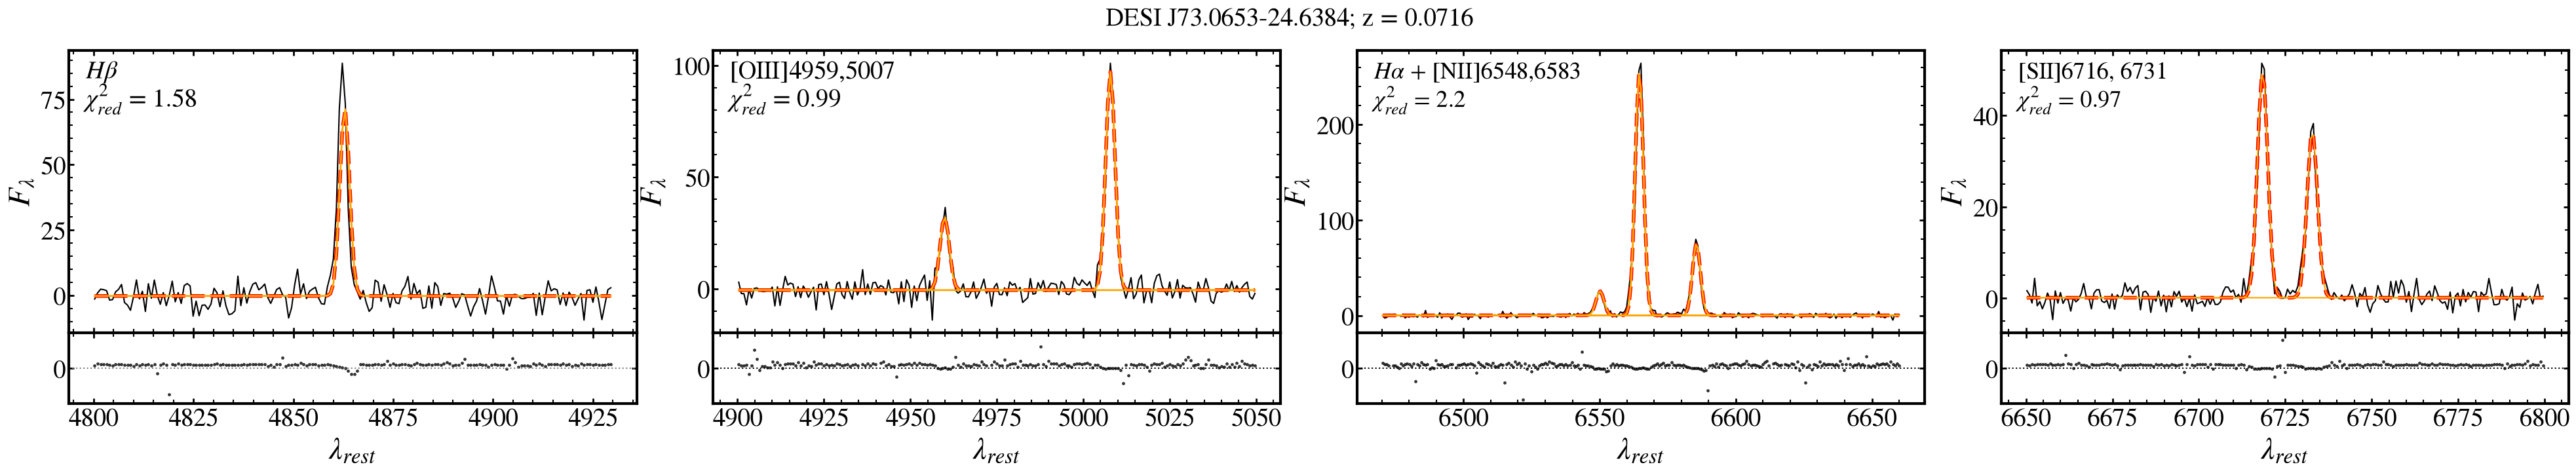

In [20]:
ii = 6099558

f_nl, h_nl = wrapper_example_fit(ii)
f_nl

In [21]:
# f_nl.savefig('01_NL_example.png')
# h_nl.writeto('../catalogs/paper_figures/Fig09a_NL.fits', overwrite = True)

## 2. Double-Peaked Candidate

In [22]:
np.nonzero(is_nl&(ha_b == 0)&(is_oiii_out&is_oiii_dbl)&(is_sii_out&is_sii_dbl&is_ha_out))[0][0:10]

array([16435, 23538, 24097, 25508, 26297, 26698, 29441, 30916, 30976,
       32037])

INFO:spectra.py:469:read_spectra: iotime 3.125 sec to read spectra from:  coadd-main-dark-27283.fits at 2026-10-05T10:47:12.719277
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.064 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.549 sec to read spectra from:  coadd-main-dark-27283.fits at 2026-10-05T10:47:17.687647
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


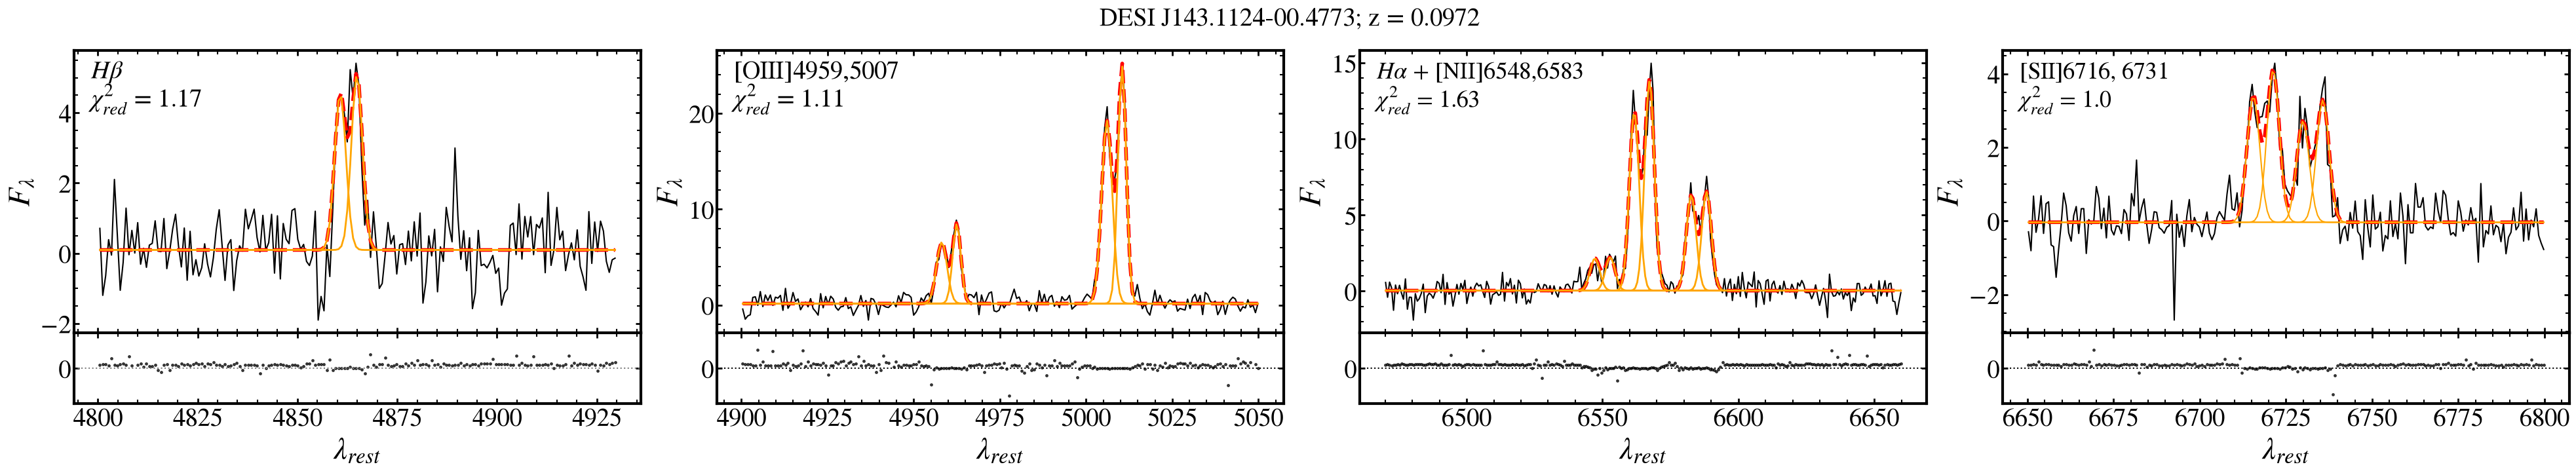

In [23]:
# 24097, 
ii = 26698
f_dbl, h_dbl = wrapper_example_fit(ii)
f_dbl

In [24]:
# f_dbl.savefig('02_DoublePeak_example.png')
# h_dbl.writeto('../catalogs/paper_figures/Fig09b_DoublePeak.fits', overwrite = True)

## 3. Outflow Candidate

In [25]:
np.nonzero(is_nl&(ha_b == 0)&(is_oiii_out&~is_oiii_dbl)&(is_sii_out&~is_sii_dbl&is_ha_out&is_hb_out))[0][0:10]

array([ 2064, 21757, 22687, 22791, 22835, 23121, 23328, 23395, 23763,
       24118])

INFO:spectra.py:469:read_spectra: iotime 5.181 sec to read spectra from:  coadd-main-dark-40910.fits at 2026-10-05T10:47:26.946595
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.511 sec to read spectra from:  coadd-main-dark-40910.fits at 2026-10-05T10:47:31.598488
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]


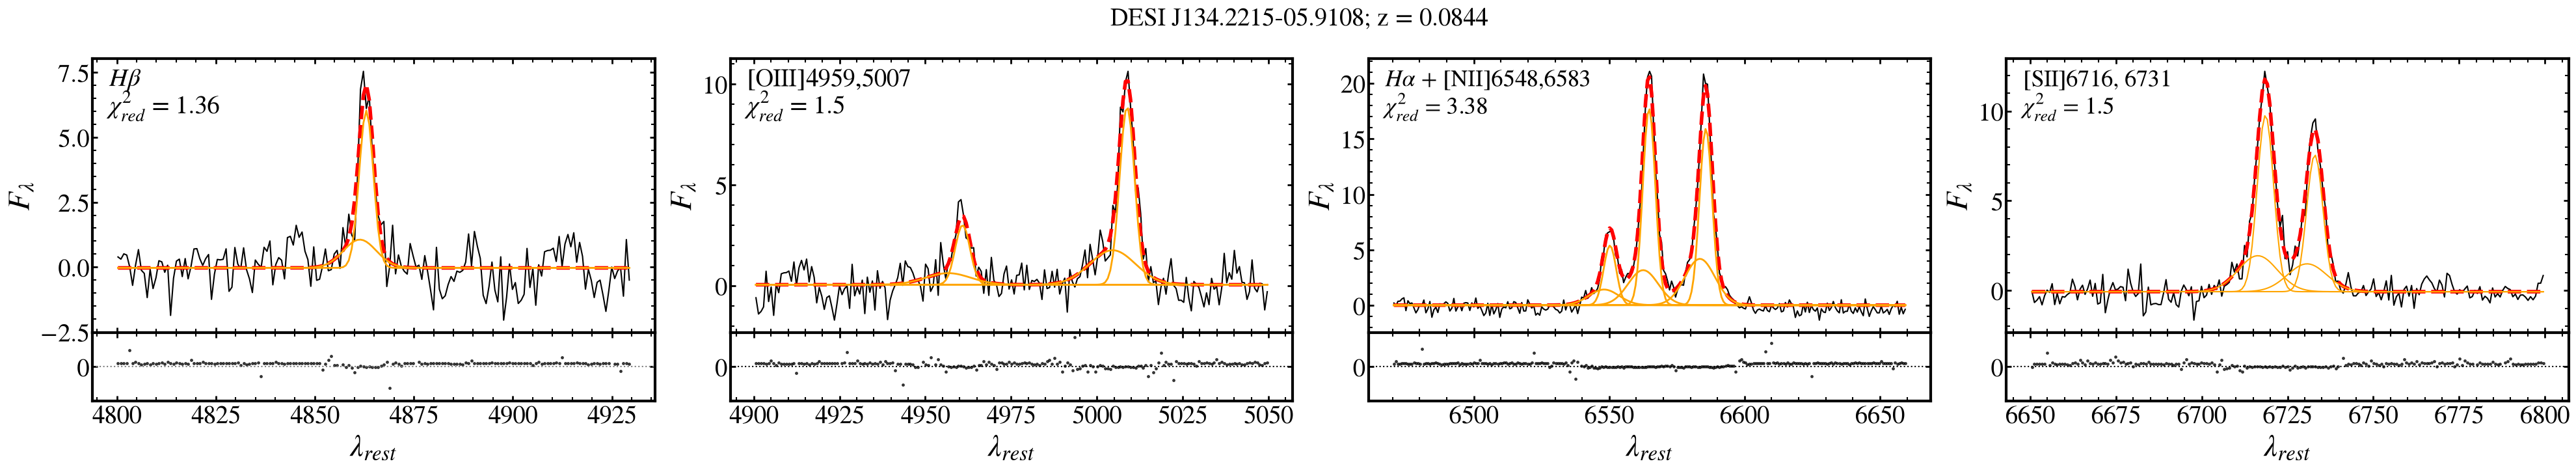

In [26]:
ii = 23328
f_out, h_out = wrapper_example_fit(ii)
f_out

In [27]:
#f_out.savefig('03_Outflows_example.png')
# h_out.writeto('../catalogs/paper_figures/Fig09c_Outflows.fits', overwrite = True)

## 4. Narrow-line + Broad Default Mode

In [28]:
np.nonzero(is_bl&(~is_oiii_out)&~is_sii_out&(is_agn|is_comp)&himass&(ha_b_fwhm > 1000))[0][0:100]

array([22020, 23261, 23298, 23928, 24049, 24105, 24230, 24361, 25001,
       25590, 26339, 27210, 29034, 29376, 29434, 29897, 30458, 31118,
       31163, 31164, 31373, 31600, 31961, 32594, 33990, 34058, 34387,
       34707, 34815, 35501, 35722, 36238, 36859, 37769, 37845, 38025,
       38321, 38718, 39200, 39308, 40385, 40414, 44916, 47322, 51331,
       52971, 54853, 57395, 57552, 57700, 58373, 58449, 59592, 60267,
       61624, 61661, 61737, 62134, 62170, 63380, 63537, 65985, 66387,
       66732, 67349, 67386, 67819, 68801, 69002, 69292, 69486, 69781,
       69784, 70616, 71219, 72057, 73821, 74281, 77156, 77779, 78205,
       78391, 80827, 80859, 81545, 82650, 82823, 84756, 85134, 85193,
       87772, 89371, 90874, 91210, 92248, 94019, 94461, 96332, 96518,
       97198])

INFO:spectra.py:469:read_spectra: iotime 1.233 sec to read spectra from:  coadd-main-bright-22537.fits at 2026-10-05T10:47:36.787087
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.213 sec to read spectra from:  coadd-main-bright-22537.fits at 2026-10-05T10:47:39.813678
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


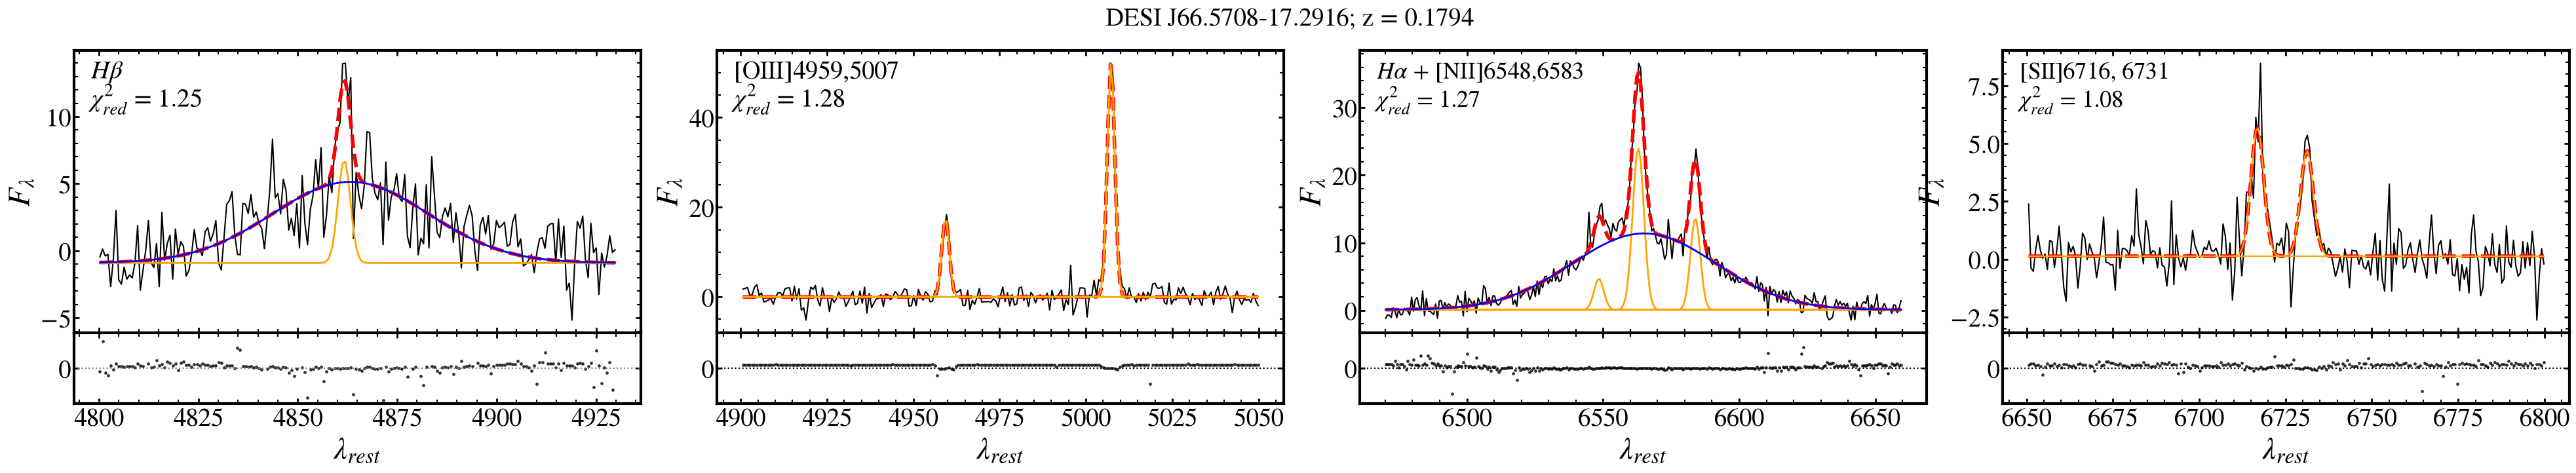

In [29]:
## 80860
ii = 77779
f_b, h_b = wrapper_example_fit(ii)
f_b

In [30]:
# f_b.savefig('04_NL_wBroad.png')
# h_b.writeto('../catalogs/paper_figures/Fig10a_NL_wBroad.fits', overwrite = True)

## 5. Double-Peaked + Broad Component

In [31]:
np.nonzero(is_bl&(ha_b != 0)&(is_sii_out&is_sii_dbl&is_ha_out)&~is_oiii_out&(ha_b_fwhm > 1000))[0][80:90]

array([3343182, 3347049, 3387987, 3450698, 3451999, 3472196, 3517184,
       3531919, 3542904, 3735184])

INFO:spectra.py:469:read_spectra: iotime 2.374 sec to read spectra from:  coadd-main-dark-4706.fits at 2026-10-05T10:47:45.149103
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.203 sec to read spectra from:  coadd-main-dark-4706.fits at 2026-10-05T10:47:48.356465
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


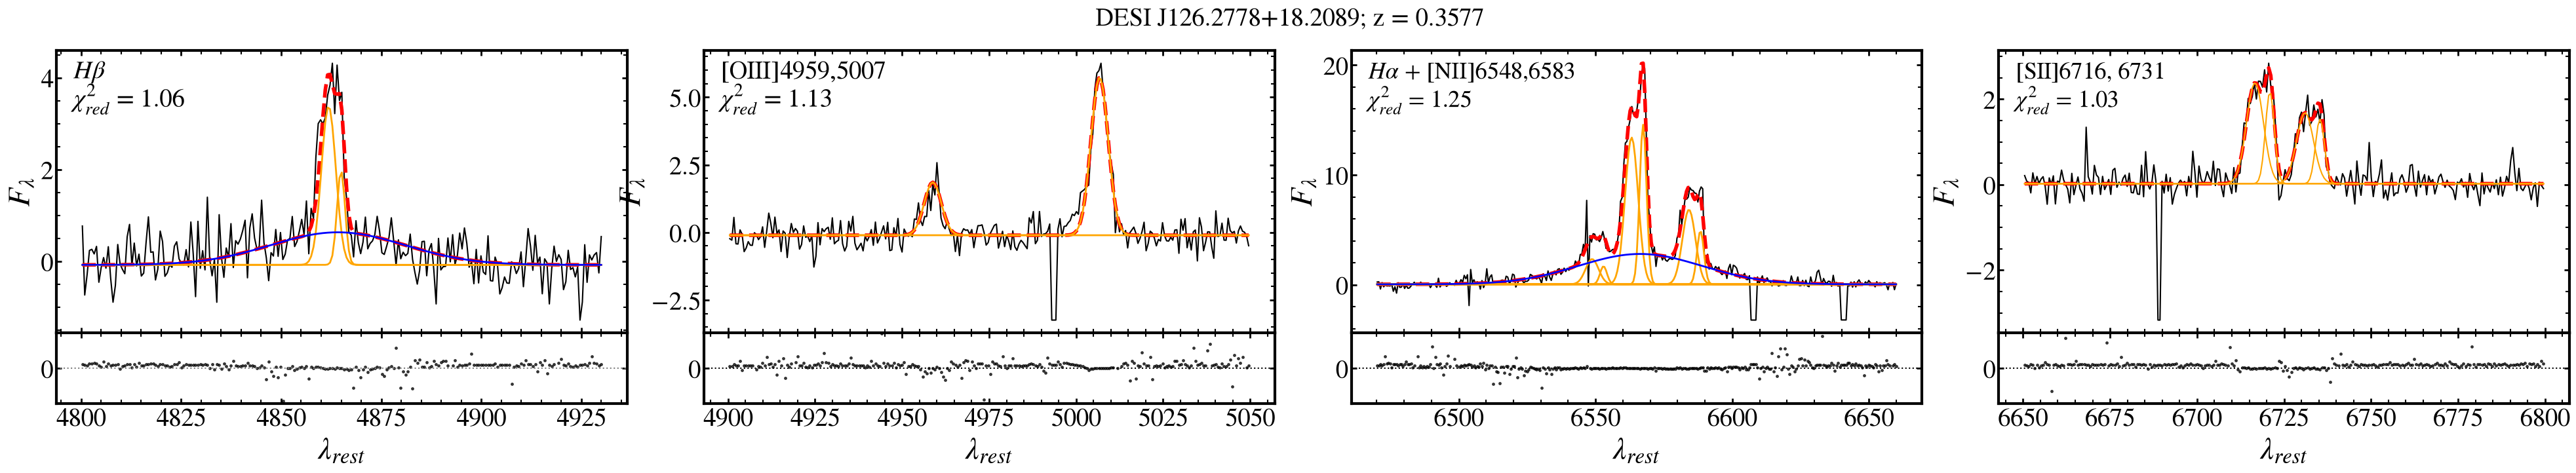

In [32]:
ii = 3343182 
f_dbl_b, h_dbl_b = wrapper_example_fit(ii)
f_dbl_b

In [33]:
# f_dbl_b.savefig('05_DoublePeak_wBroad.png')
# h_dbl_b.writeto('../catalogs/paper_figures/Fig10b_DoublePeak_wBroad.fits', overwrite = True)

## 6. Outflow + Broad Component

In [34]:
np.nonzero(is_default&is_bl&(ha_b != 0)&(is_oiii_out&~is_oiii_dbl)&~is_sii_out&(ha_b_fwhm > 1000))[0][100:120]

array([131492, 133425, 134336, 134583, 134910, 136584, 138451, 140684,
       140734, 141757, 144707, 145715, 145731, 146191, 146543, 147839,
       148678, 148798, 149312, 149821])

INFO:spectra.py:469:read_spectra: iotime 1.692 sec to read spectra from:  coadd-main-bright-18572.fits at 2026-10-05T10:47:53.076998
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.061 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.133 sec to read spectra from:  coadd-main-bright-18572.fits at 2026-10-05T10:47:55.756465
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.064 [sec]


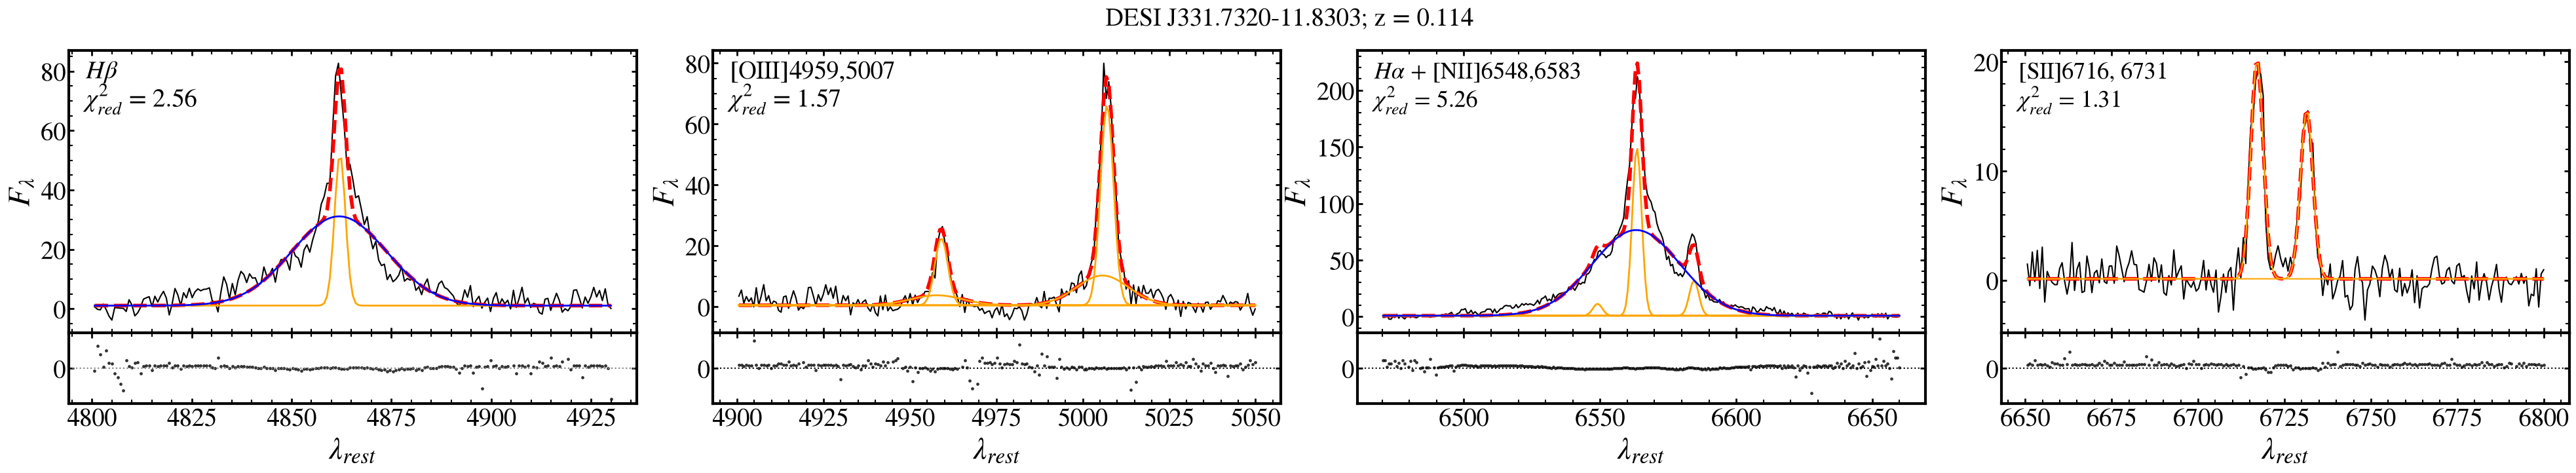

In [35]:
ii = 149312
f_out_b, h_out_b = wrapper_example_fit(ii)
f_out_b

In [36]:
# f_out_b.savefig('06_Outflows_wBroad.png')
# h_out_b.writeto('../catalogs/paper_figures/Fig10c_Outflows_wBroad.fits', overwrite = True)

### 7. EBL - without [OIII] Outflow

In [37]:
np.nonzero(is_ebl&(is_agn|is_comp)&(~is_oiii_out)&is_bl)[0][200:220]

array([600784, 601989, 609113, 611498, 614695, 621200, 623374, 626210,
       634556, 640111, 641061, 650554, 654530, 655872, 663294, 669446,
       669502, 671371, 671967, 682155])

INFO:spectra.py:469:read_spectra: iotime 2.196 sec to read spectra from:  coadd-main-bright-26895.fits at 2026-10-05T10:48:00.692495
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.314 sec to read spectra from:  coadd-main-bright-26895.fits at 2026-10-05T10:48:04.196500
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


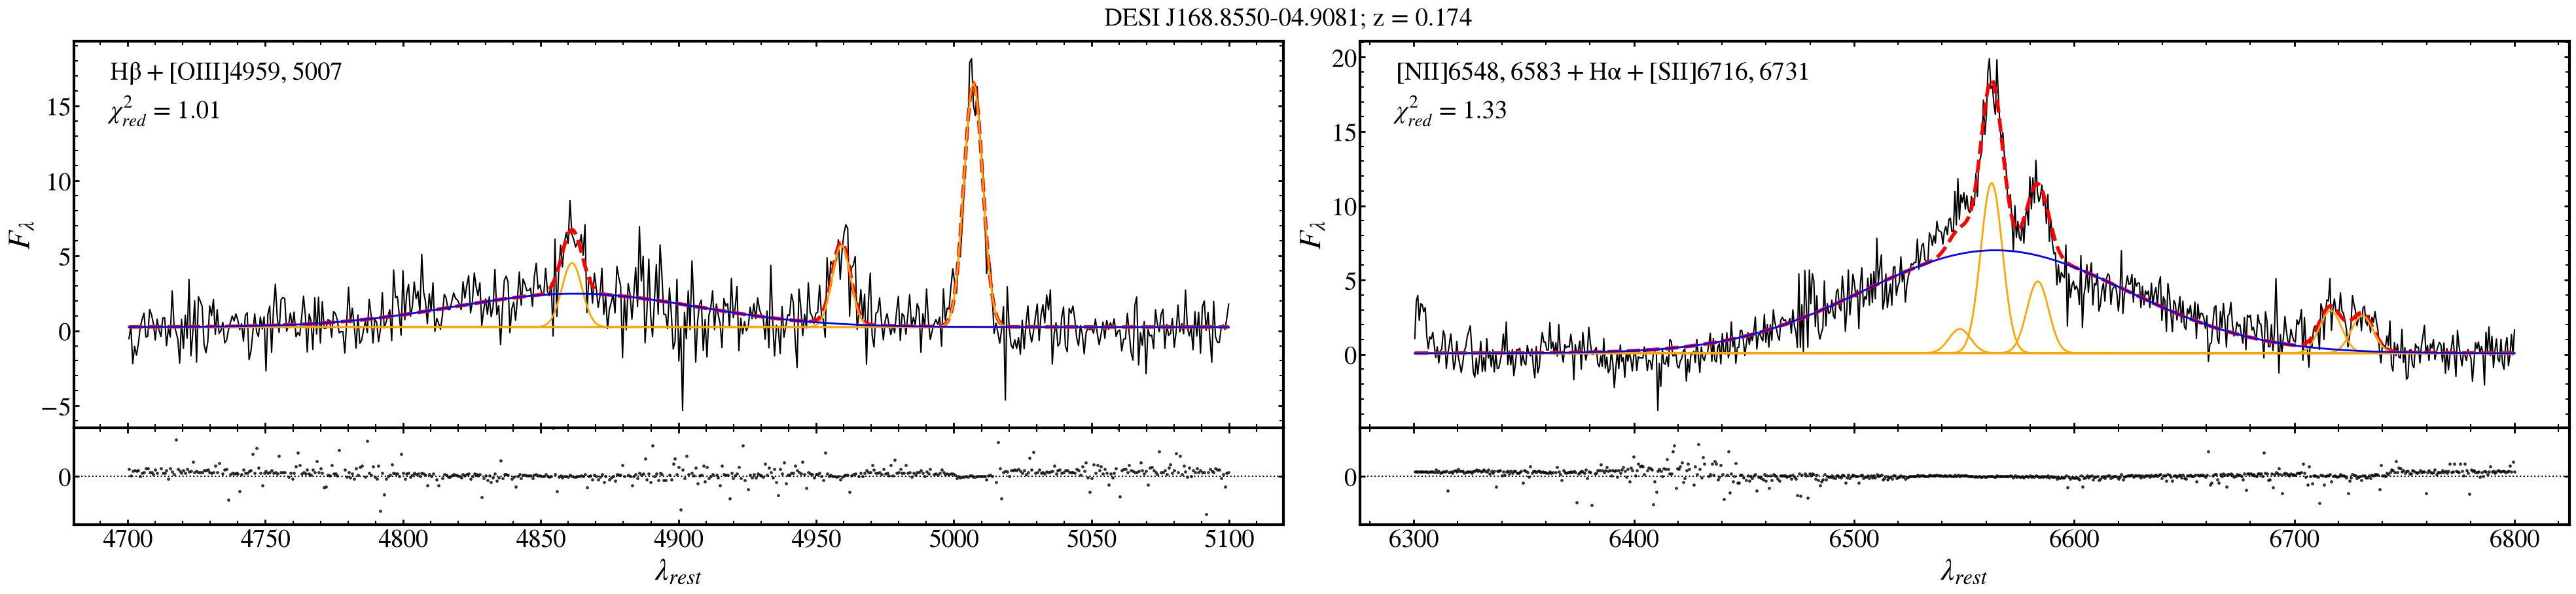

In [38]:
ii = 621200
f_ebl, h_ebl = wrapper_example_fit(ii, ver = 'ebl')
f_ebl

In [39]:
# f_ebl.savefig('07_EBL_noOutflows.png')
# h_ebl.writeto('../catalogs/paper_figures/Fig11a_EBL_noOutflows.fits', overwrite = True)

## 8. EBL - with [OIII] Outflow

In [40]:
np.nonzero(is_ebl&(is_agn|is_comp)&(is_oiii_out&~is_oiii_dbl))[0][110:120]

array([123835, 123850, 125322, 131644, 132682, 133181, 133369, 135062,
       135991, 137007])

INFO:spectra.py:469:read_spectra: iotime 0.584 sec to read spectra from:  coadd-main-bright-22659.fits at 2026-10-05T10:48:07.780191
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.062 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.096 sec to read spectra from:  coadd-main-bright-22659.fits at 2026-10-05T10:48:10.209349
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


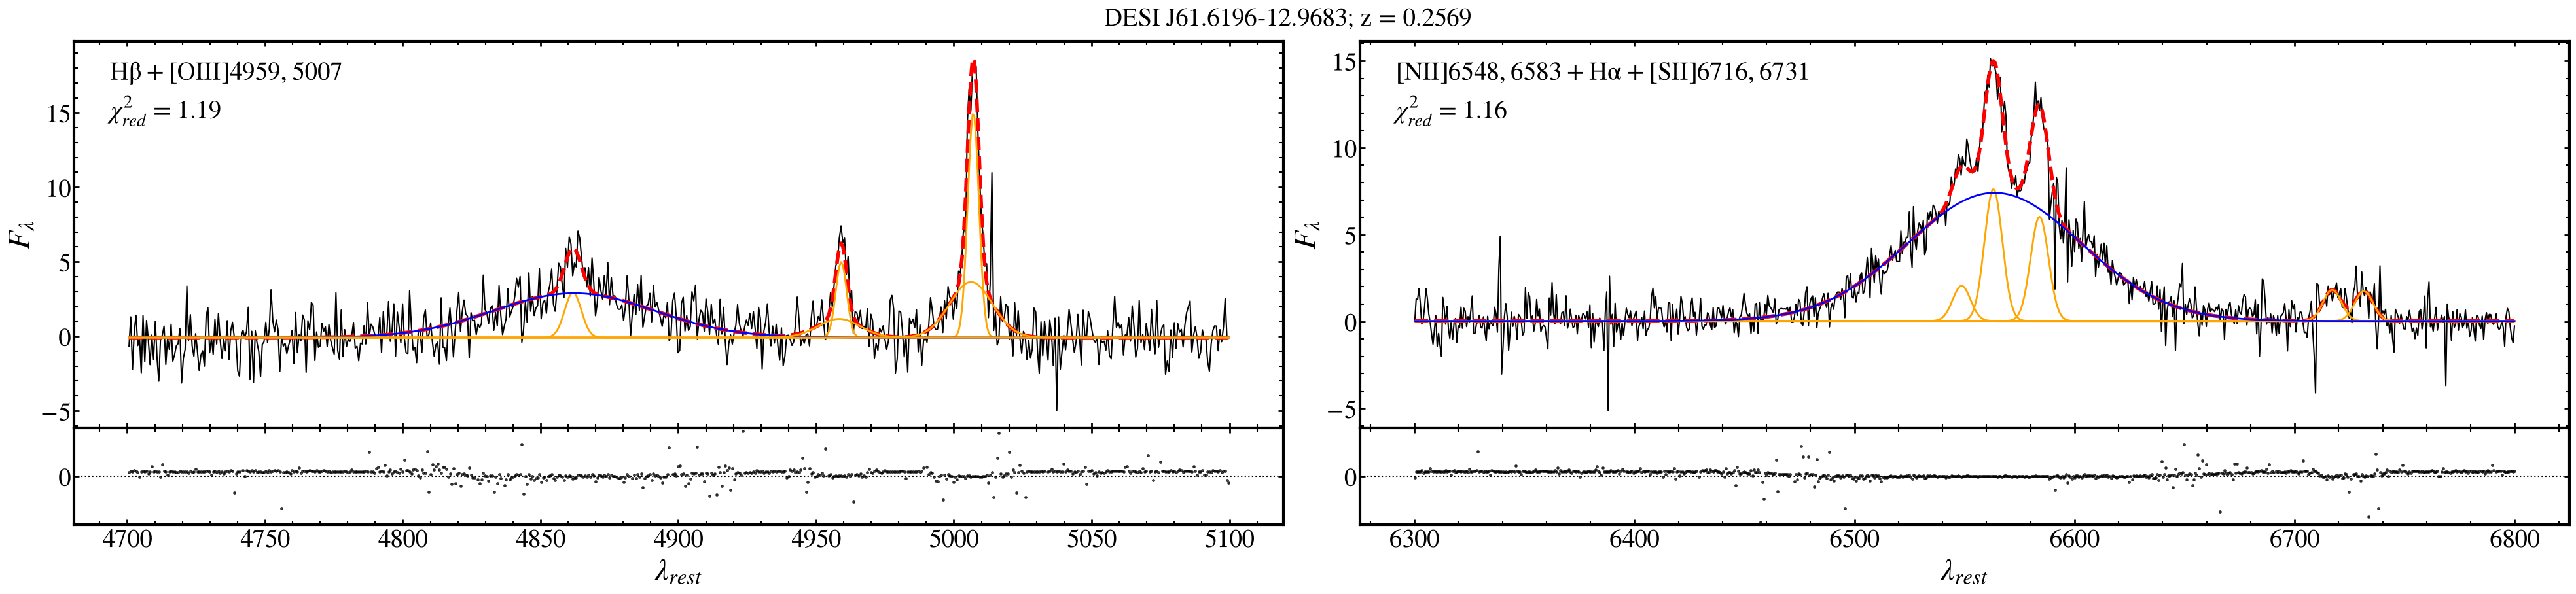

In [41]:
ii = 123850
f_ebl_out, h_ebl_out = wrapper_example_fit(ii, ver = 'ebl')
f_ebl_out

In [42]:
# f_ebl_out.savefig('08_EBL_wOutflows.png')
# h_ebl_out.writeto('../catalogs/paper_figures/Fig11b_EBL_wOutflows.fits', overwrite = True)

## 2. Double-Peaked Candidates

### 2a. Only in [SII], [NII], and Ha

In [43]:
np.nonzero(is_nl&(ha_b == 0)&(is_sii_out&is_sii_dbl&is_ha_out)&~is_oiii_out)[0][1000:1020]

array([439562, 439910, 439949, 440445, 443063, 443092, 443113, 443803,
       444177, 444192, 444211, 444388, 444839, 445058, 445218, 445514,
       445826, 446497, 446836, 446848])

INFO:spectra.py:469:read_spectra: iotime 1.365 sec to read spectra from:  coadd-sv1-bright-17675.fits at 2026-10-05T10:48:14.006322
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.061 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.188 sec to read spectra from:  coadd-sv1-bright-17675.fits at 2026-10-05T10:48:16.769979
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.063 [sec]


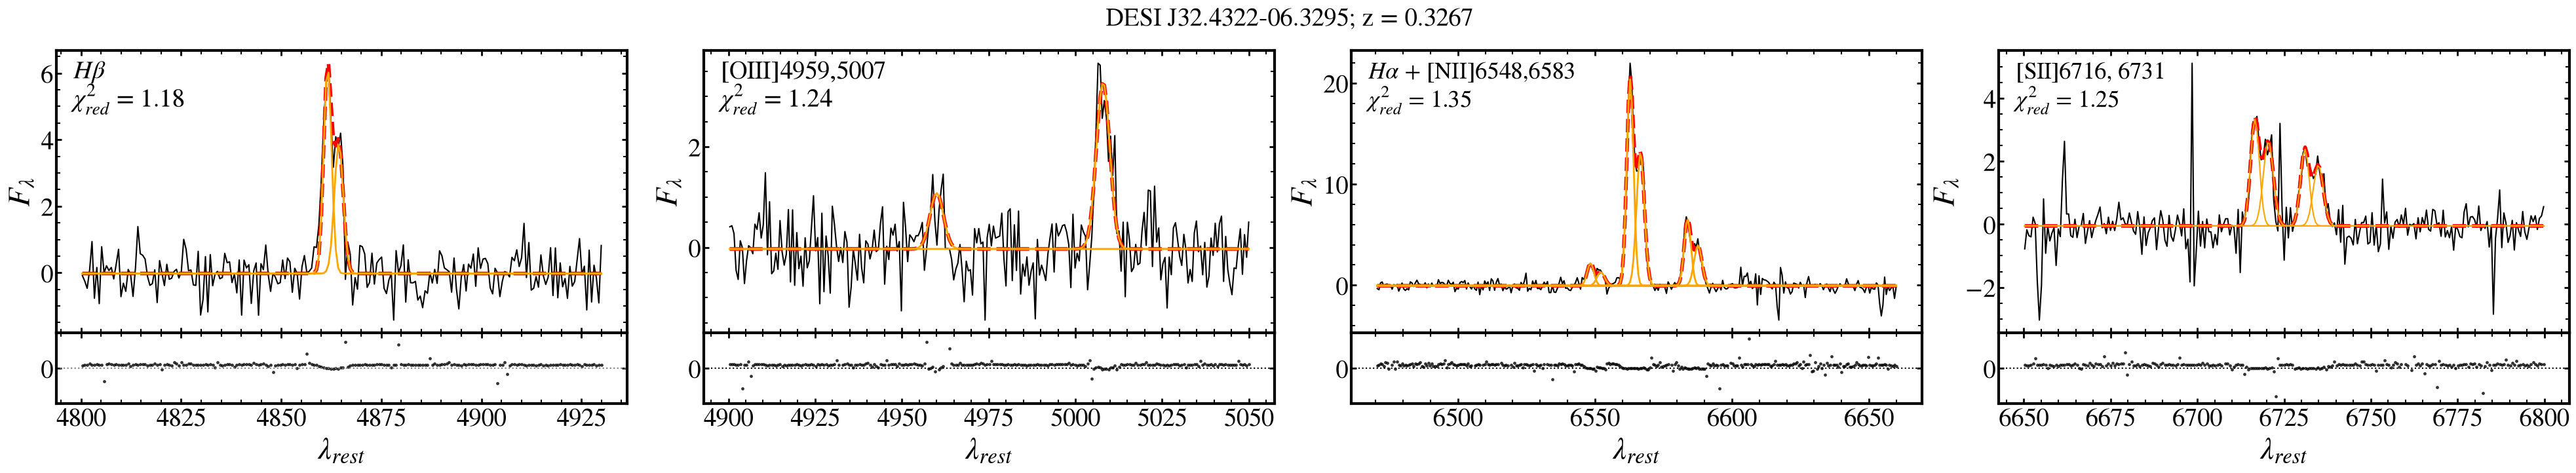

In [44]:
ii = 444177
f_sii_dbl, h_sii_dbl = wrapper_example_fit(ii)
f_sii_dbl

In [45]:
# f_sii_dbl.savefig('02_SII_double.png')

### 2b. Only in [OIII]

In [46]:
np.nonzero(is_nl&(ha_b == 0)&(is_oiii_out&is_oiii_dbl)&~is_sii_out)[0][-40:-20]

array([6073574, 6074285, 6074567, 6074830, 6075052, 6076980, 6077737,
       6078625, 6078707, 6079284, 6079336, 6081307, 6081648, 6082318,
       6083615, 6084555, 6085834, 6087314, 6087762, 6088422])

INFO:spectra.py:469:read_spectra: iotime 1.212 sec to read spectra from:  coadd-main-bright-519.fits at 2026-10-05T10:48:20.797926
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.121 sec to read spectra from:  coadd-main-bright-519.fits at 2026-10-05T10:48:23.280107
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


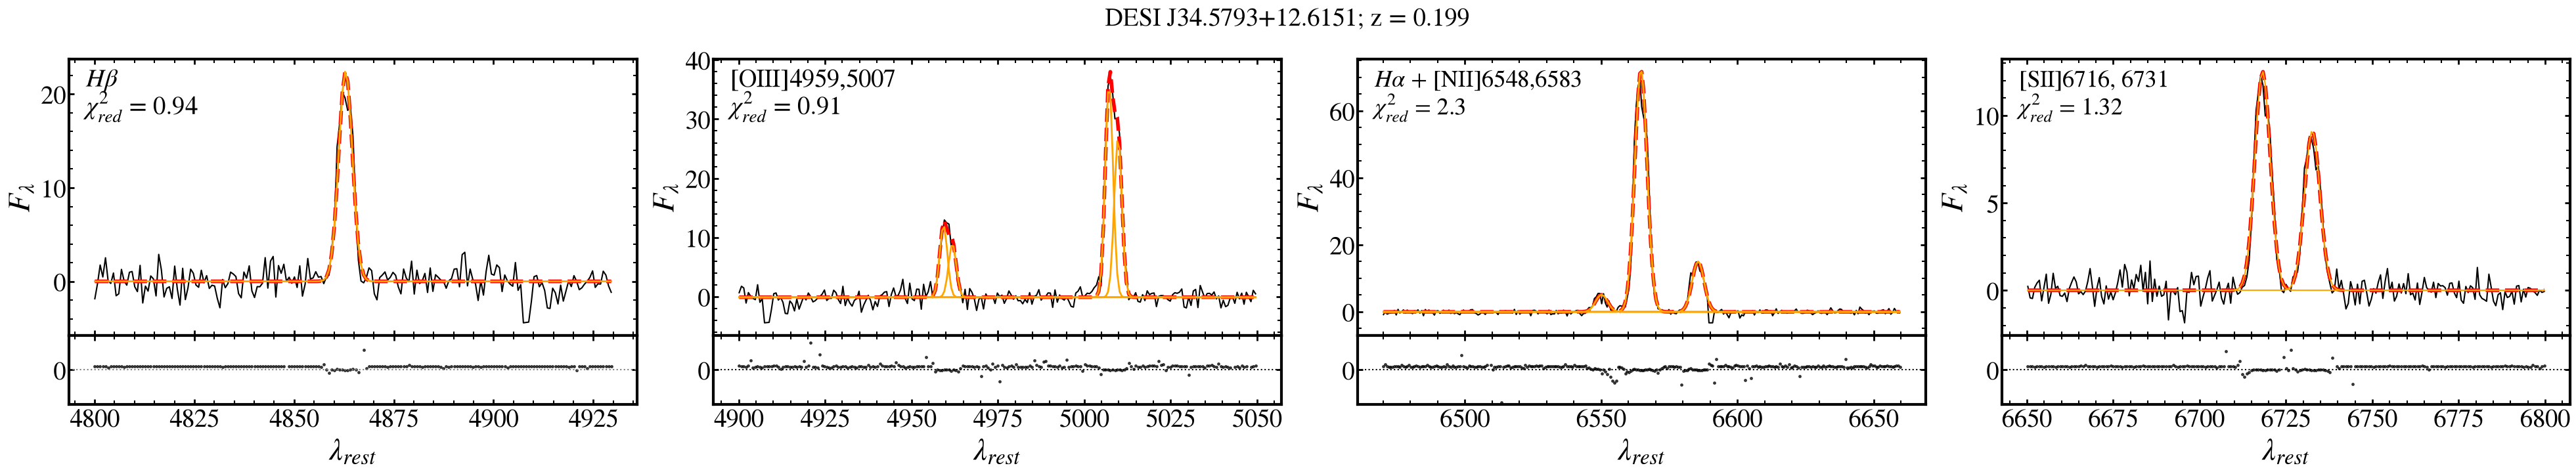

In [47]:
ii = 6085834
f_oiii_dbl, h_oiii_dbl = wrapper_example_fit(ii)
f_oiii_dbl

In [48]:
#f_oiii_dbl.savefig('03_OIII_double.png')

## 3. Outflows

### 3a. Only in [NII], [SII], and Ha

In [49]:
np.nonzero(is_nl&(ha_b == 0)&(is_sii_out&~is_sii_dbl&is_ha_out)&~is_oiii_out)[0][-40:]

array([6062856, 6063050, 6063849, 6063917, 6063956, 6064758, 6064771,
       6065144, 6065194, 6065201, 6065891, 6066241, 6066674, 6068769,
       6069535, 6071228, 6071521, 6074031, 6077147, 6079264, 6080696,
       6081464, 6083484, 6084665, 6088504, 6089463, 6090804, 6091658,
       6092366, 6092993, 6093273, 6093814, 6097523, 6097777, 6097794,
       6097911, 6097973, 6098324, 6098520, 6099326])

INFO:spectra.py:469:read_spectra: iotime 0.849 sec to read spectra from:  coadd-main-backup-27649.fits at 2026-10-05T10:48:26.738914
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.080 sec to read spectra from:  coadd-main-backup-27649.fits at 2026-10-05T10:48:29.151827
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


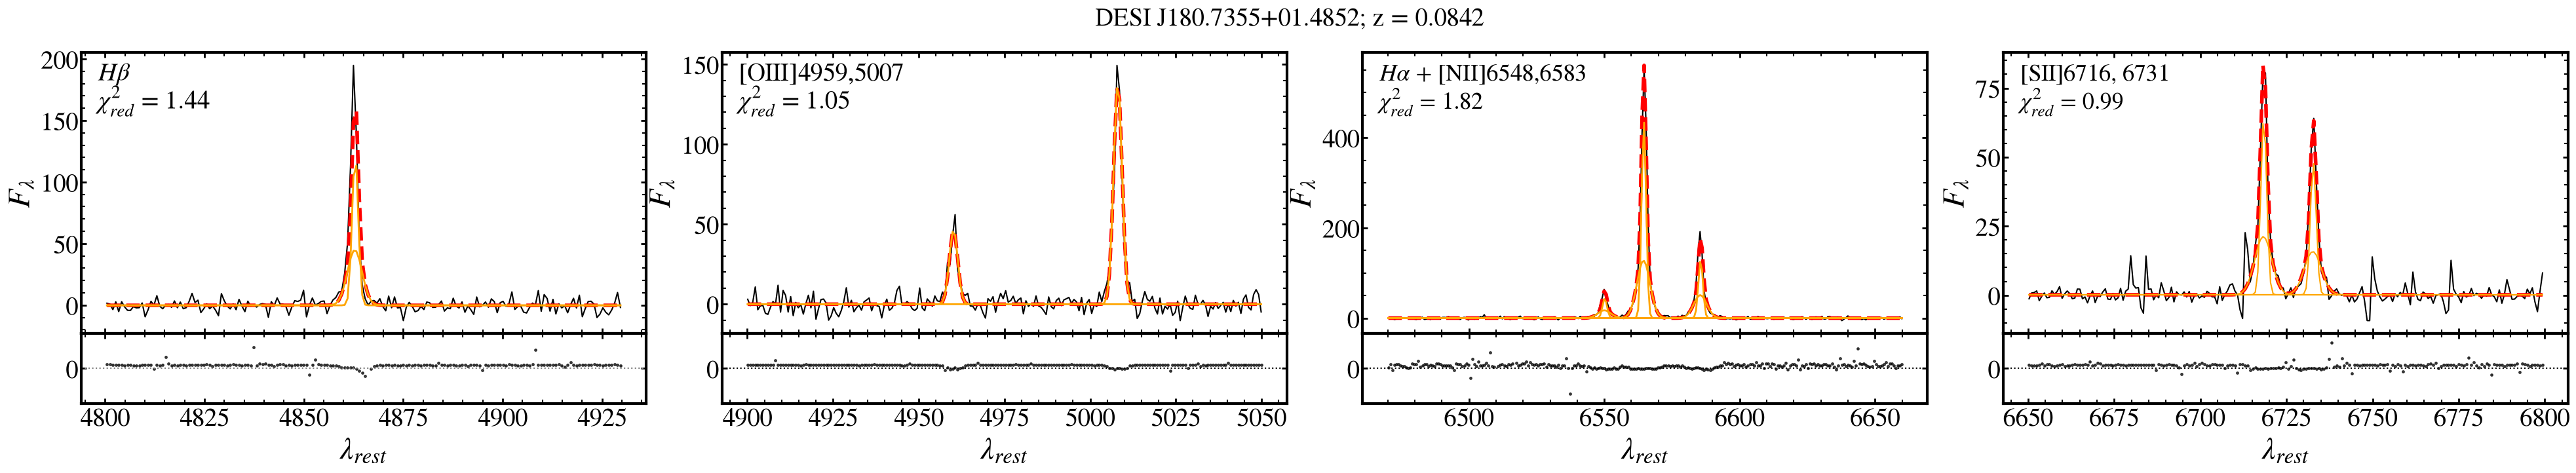

In [50]:
ii = 6099326
f_out_sii, h_out_sii = wrapper_example_fit(ii)
f_out_sii

In [51]:
# f_out_sii.savefig('05_SII_Outflow.png')

### 3b. Only in [OIII]

In [52]:
np.nonzero(is_bl&(ha_b_fwhm > 1000)&(is_oiii_out&~is_oiii_dbl)&~is_sii_out)[0][1400:1410]

array([1177716, 1178465, 1178947, 1179648, 1181955, 1182332, 1185065,
       1185105, 1185499, 1186860])

INFO:spectra.py:469:read_spectra: iotime 1.811 sec to read spectra from:  coadd-main-bright-22945.fits at 2026-10-05T10:48:33.425033
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.287 sec to read spectra from:  coadd-main-bright-22945.fits at 2026-10-05T10:48:36.688240
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


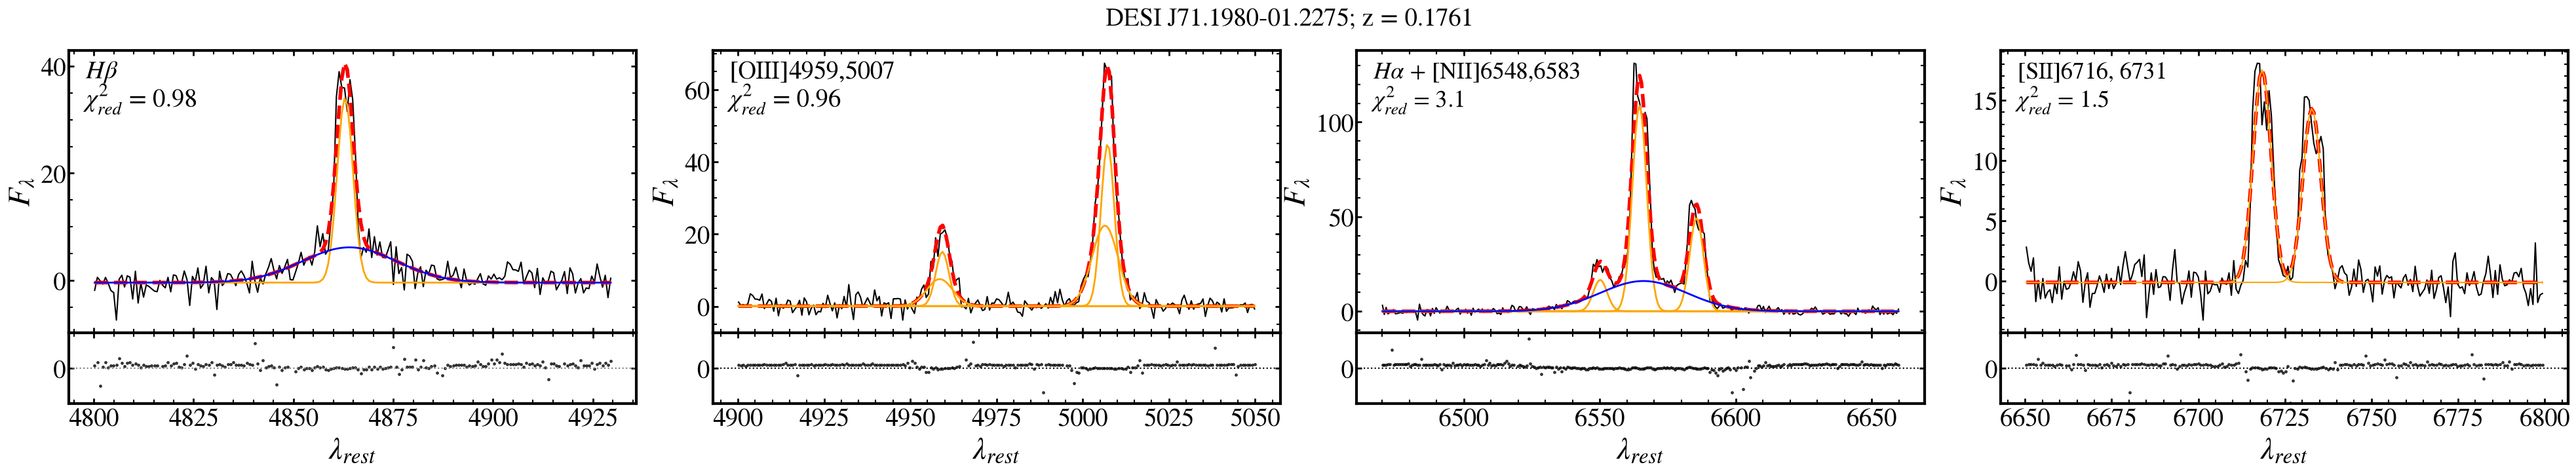

In [53]:
ii = 1178947 
f_out_oiii, h_out_oiii = wrapper_example_fit(ii)
f_out_oiii

In [54]:
#f_out_oiii.savefig('05_OIII_Outflow.png')

### 4. Broad-Line Candidate

In [55]:
np.nonzero(is_bl&(is_oiii_out)&~is_sii_out&(is_agn|is_comp)&lomass)[0][0:100]

array([  60518,  115975,  151456,  208270,  212350,  288760,  333400,
        343213,  415176,  425287,  505206,  537508,  562749,  615990,
        623568,  722173,  731566,  749459,  780671,  840433,  844607,
        849553,  894168,  971804, 1061804, 1093826, 1106823, 1146719,
       1157070, 1192819, 1282497, 1438726, 1457235, 1502230, 1524192,
       1531064, 1535305, 1555822, 1570390, 1610000, 1641123, 1654421,
       1671475, 1730488, 1813309, 1907970, 1932545, 2056246, 2094631,
       2099890, 2158381, 2159041, 2186932, 2232590, 2248485, 2262037,
       2343116, 2351910, 2417563, 2425779, 2487980, 2545802, 2547382,
       2686062, 2731362, 2790201, 2790625, 2801109, 2811032, 2833616,
       2904877, 2926034, 2944686, 2945816, 2963264, 2965154, 2984168,
       2989008, 3008808, 3032300, 3071582, 3071589, 3073274, 3078730,
       3104429, 3116341, 3184718, 3251173, 3312349, 3322397, 3359556,
       3360252, 3457617, 3501136, 3542322, 3545428, 3572339, 3588228,
       3607535, 3617

INFO:spectra.py:469:read_spectra: iotime 0.121 sec to read spectra from:  coadd-main-dark-17264.fits at 2026-10-05T10:48:39.840183
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.032 sec to read spectra from:  coadd-main-dark-17264.fits at 2026-10-05T10:48:42.046874
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


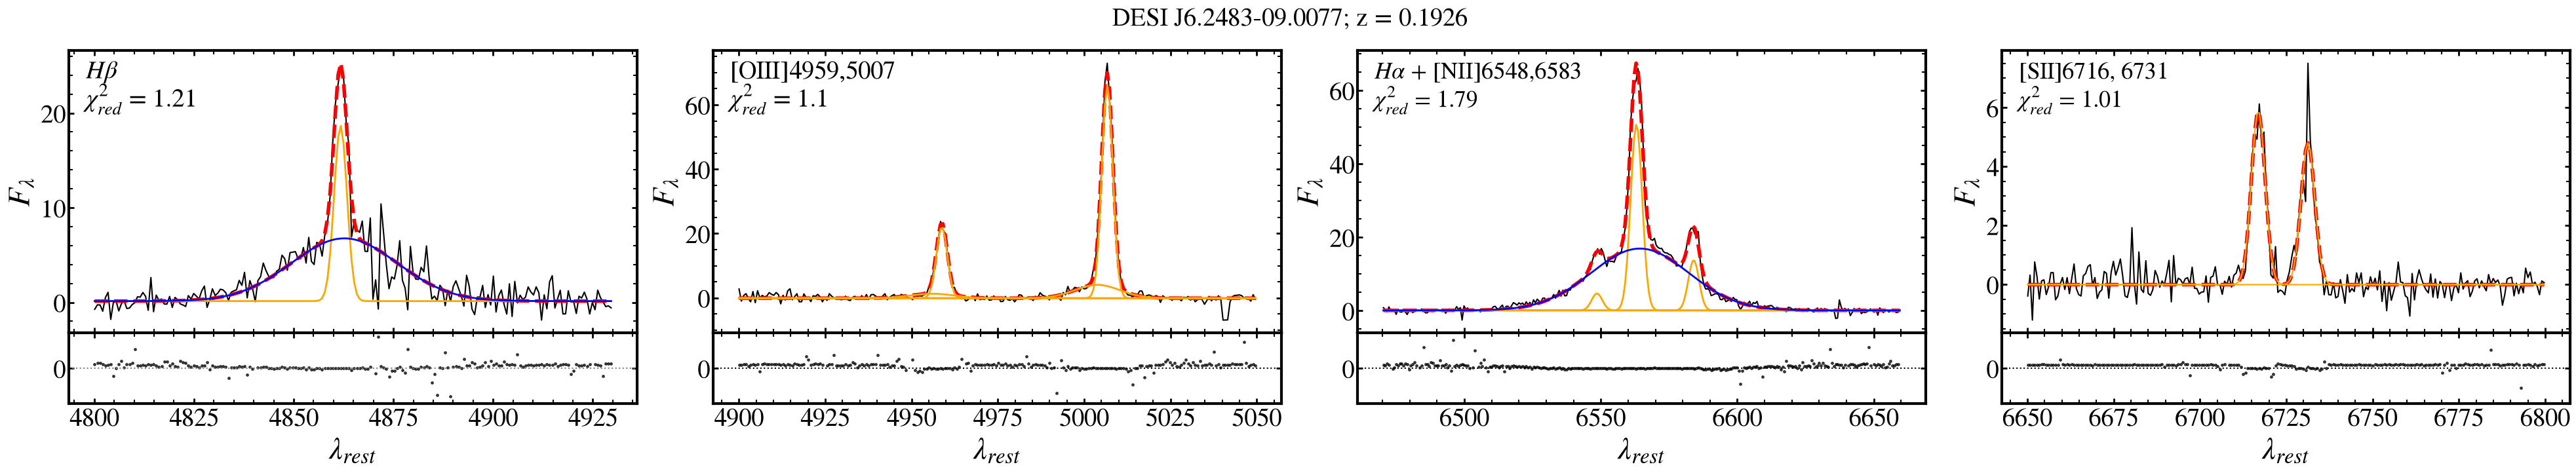

In [56]:
ii = 208270
f_b, h_b = wrapper_example_fit(ii)
f_b

In [57]:
# f_b.savefig('07_Broad_Line.png')

### Outflows with Broad Lines

In [58]:
np.nonzero(is_bl&(is_sii_out&is_ha_out)&(is_oiii_out)&(is_agn|is_comp)&(ha_b_fwhm > 1000))[0][100:120]

array([ 940477,  940662,  949523,  950151,  958705,  999609, 1006288,
       1008550, 1019505, 1034060, 1055161, 1067588, 1077485, 1078344,
       1101469, 1162472, 1178594, 1179634, 1184705, 1186490])

INFO:spectra.py:469:read_spectra: iotime 3.541 sec to read spectra from:  coadd-main-bright-27187.fits at 2026-10-05T10:48:47.999917
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.061 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.352 sec to read spectra from:  coadd-main-bright-27187.fits at 2026-10-05T10:48:51.655865
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


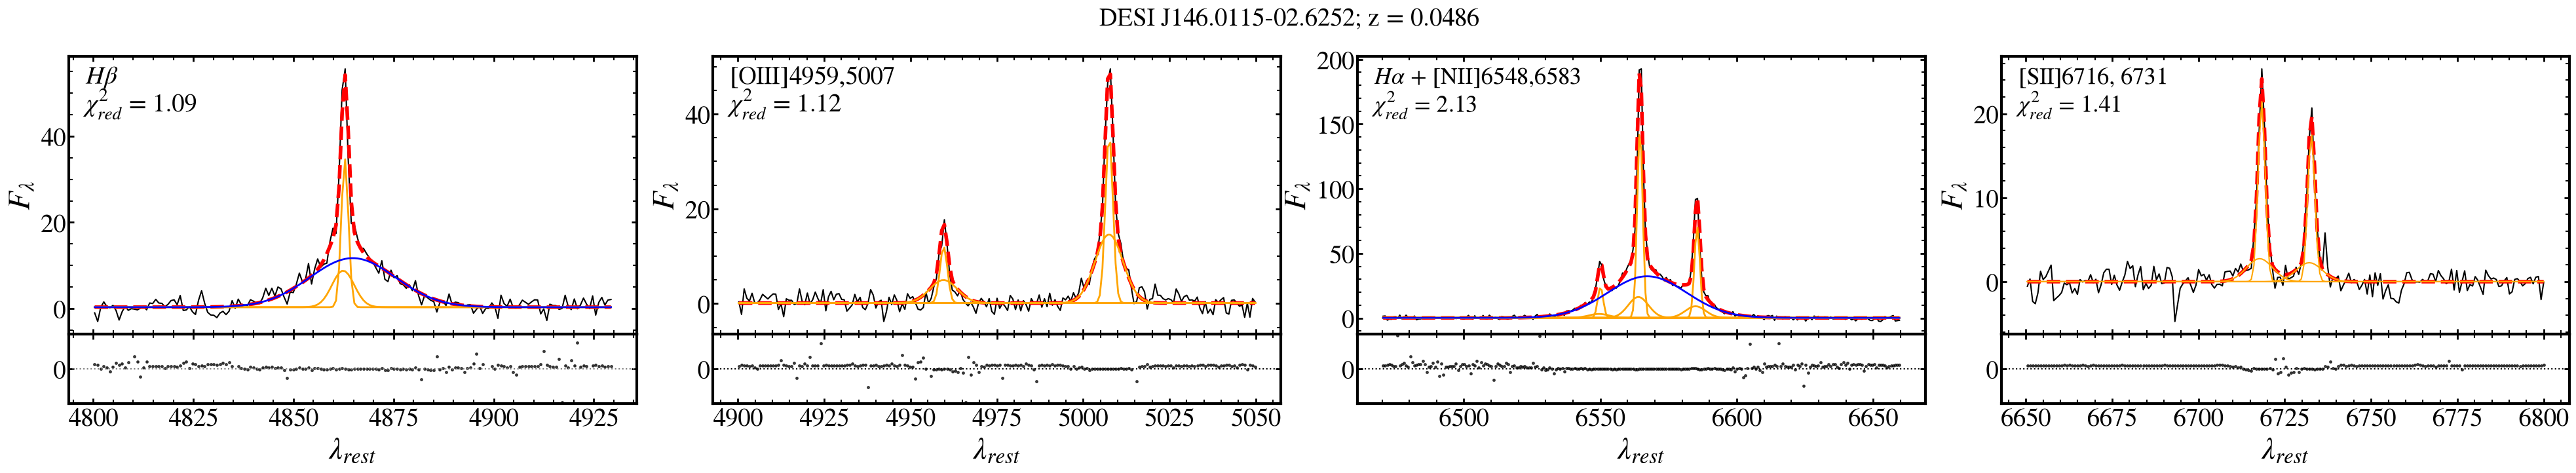

In [59]:
ii = 940477
f_out_b, h_out_b = wrapper_example_fit(ii)
f_out_b

In [60]:
# f_out_b.savefig('outflow_bl.png')

---